# Clayton Kershaw | Five-Year Statcast Performance Review (2015–2019)

**Goal:** Analyze how Kershaw's velocity, pitch mix, movement, release point, launch angle, opposing exit velocity, and plate-appearance outcomes changed from 2015 through 2019.

**Stack:** Python · pandas · NumPy · Matplotlib · seaborn · statsmodels (LOWESS) · Plotly · `pybaseball` (Statcast ingestion).


In [5]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from statsmodels.nonparametric.smoothers_lowess import lowess
import plotly.express as px

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)

PLAYER_ID = 477132  # Clayton Kershaw's MLBAM ID
YEARS = range(2015, 2020)
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Match the original project's March 31–October 31 query window in each season.
DATE_RANGES = {year: (f"{year}-03-31", f"{year}-10-31") for year in YEARS}
# Optional: False matches the project's inclusive game-type scope; True keeps only regular-season games.
REGULAR_SEASON_ONLY = False

## 1 · Pull and validate Clayton Kershaw's pitching data







In [6]:
def load_data(force_download=False):
    frames = []
    for year, (start, end) in DATE_RANGES.items():
        path = DATA_DIR / f"kershaw_statcast_{year}.csv"
        if path.exists() and not force_download:
            season_df = pd.read_csv(path, low_memory=False)
            print(f"Loaded {year} cache: {len(season_df):,} pitches")
        else:
            try:
                from pybaseball import statcast_pitcher
            except ImportError as exc:
                raise ImportError("Run: pip install -r requirements.txt") from exc
            print(f"Downloading {year} Statcast data ({start} to {end})...")
            season_df = statcast_pitcher(start, end, PLAYER_ID)
            if season_df.empty:
                raise ValueError(f"No records returned for {year}. Check the connection/date range.")
            season_df.to_csv(path, index=False)
            print(f"Saved: {path}")
        frames.append(season_df)

    return pd.concat(frames, ignore_index=True)

raw = load_data()
print(f"Total rows: {len(raw):,} | Columns: {raw.shape[1]}")

Gathering Player Data
Saved: data/kershaw_statcast_2015.csv
Gathering Player Data
Saved: data/kershaw_statcast_2016.csv
Gathering Player Data
Saved: data/kershaw_statcast_2017.csv
Gathering Player Data
Saved: data/kershaw_statcast_2018.csv
Gathering Player Data
Saved: data/kershaw_statcast_2019.csv
Total rows: 14,572 | Columns: 119


In [7]:
required = ["game_date", "game_year", "type", "events", "pitch_type",
            "release_speed", "effective_speed", "launch_speed", "launch_angle",
            "pfx_x", "pfx_z", "ax", "ay", "az", "vx0", "vy0", "vz0",
            "release_pos_x", "release_pos_y", "release_pos_z"]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Expected Statcast fields are missing: {missing}")

df = raw.copy()
df["game_date"] = pd.to_datetime(df["game_date"], errors="coerce")
df = df.dropna(subset=["game_date"])
df["Year"] = df["game_date"].dt.year.astype(int)
df = df[df["Year"].isin(YEARS)].copy()
if REGULAR_SEASON_ONLY:
    df = df[df["game_type"].eq("R")].copy()

numeric_cols = ["release_speed", "effective_speed", "launch_speed", "launch_angle",
                "pfx_x", "pfx_z", "ax", "ay", "az", "vx0", "vy0", "vz0",
                "release_pos_x", "release_pos_y", "release_pos_z"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Full pitch log for counts/outcomes; valid pitch-type rows for mechanics and pitch mix.
all_pitches = df.copy()
mechanics = df[df["pitch_type"].notna() & df["pitch_type"].ne("")].copy()
# Statcast's X indicates a ball put into play. Exclude missing / zero exit-velocity measurements.
batted_balls = df[df["type"].eq("X") & df["launch_speed"].gt(0)].copy()
# 'events' is populated at plate-appearance completion, not for every pitch.
plate_appearances = df[df["events"].notna() & df["events"].ne("")].copy()

print(f"All pitches: {len(all_pitches):,}")
print(f"Pitches with a known pitch type: {len(mechanics):,}")
print(f"Batted balls with measured exit velocity: {len(batted_balls):,}")
print(f"Recorded plate-appearance events: {len(plate_appearances):,}")

display(pd.DataFrame({
    "pitches": all_pitches.groupby("Year").size(),
    "games": all_pitches.groupby("Year")["game_date"].nunique(),
    "batted_balls_with_exit_velo": batted_balls.groupby("Year").size(),
    "recorded_pa_events": plate_appearances.groupby("Year").size(),
}).fillna(0).astype(int))

All pitches: 14,572
Pitches with a known pitch type: 14,389
Batted balls with measured exit velocity: 2,452
Recorded plate-appearance events: 3,870


,pitches,games,batted_balls_with_exit_velo,recorded_pa_events
Year,,,,
2015,3644,36,550,954
2016,2457,26,421,646
2017,2974,32,497,791
2018,2720,31,522,742
2019,2777,31,462,737


## 2 · YOY KPI scorecard


In [8]:
mechanics_summary = mechanics.groupby("Year").agg(
    pitches=("release_speed", "size"),
    avg_release_mph=("release_speed", "mean"),
    avg_effective_mph=("effective_speed", "mean"),
    avg_horizontal_movement_ft=("pfx_x", "mean"),
    avg_vertical_movement_ft=("pfx_z", "mean"),
    avg_ax=("ax", "mean"), avg_ay=("ay", "mean"), avg_az=("az", "mean"),
    avg_vx0=("vx0", "mean"), avg_vy0=("vy0", "mean"), avg_vz0=("vz0", "mean"),
    avg_release_x_ft=("release_pos_x", "mean"),
    avg_release_y_ft=("release_pos_y", "mean"),
    avg_release_z_ft=("release_pos_z", "mean"),
)

contact_summary = batted_balls.groupby("Year").agg(
    measured_batted_balls=("launch_speed", "count"),
    avg_exit_velocity_mph=("launch_speed", "mean"),
    avg_launch_angle_deg=("launch_angle", "mean"),
    hard_hit_rate_pct=("launch_speed", lambda s: 100 * s.ge(95).mean()),
)

yearly = mechanics_summary.join(contact_summary)
output_cols = ["pitches", "avg_release_mph", "avg_effective_mph",
               "avg_exit_velocity_mph", "avg_launch_angle_deg", "hard_hit_rate_pct"]
display(yearly[output_cols].round(2))
yearly.round(4).to_csv(OUTPUT_DIR / "kershaw_yearly_summary.csv")

,pitches,avg_release_mph,avg_effective_mph,avg_exit_velocity_mph,avg_launch_angle_deg,hard_hit_rate_pct
Year,,,,,,
2015,3639,89.03,88.41,85.20,9.24,25.82
2016,2454,88.89,88.45,87.40,10.76,29.93
2017,2900,88.16,87.73,85.86,10.51,28.57
2018,2716,86.69,86.59,87.97,9.16,36.21
2019,2680,86.21,85.77,88.13,12.34,35.93


In [9]:
first, last = yearly.loc[2015], yearly.loc[2019]

def print_change(label, col, unit):
    start, end = first[col], last[col]
    if pd.notna(start) and pd.notna(end):
        print(f"{label}: {start:.2f}{unit} (2015) → {end:.2f}{unit} (2019) | change {end-start:+.2f}{unit}")

print_change("Avg release speed", "avg_release_mph", " mph")
print_change("Opposing exit velocity", "avg_exit_velocity_mph", " mph")
print_change("Opposing launch angle", "avg_launch_angle_deg", "°")
print_change("Hard-hit rate (95+ mph)", "hard_hit_rate_pct", " percentage points")



Avg release speed: 89.03 mph (2015) → 86.21 mph (2019) | change -2.82 mph
Opposing exit velocity: 85.20 mph (2015) → 88.13 mph (2019) | change +2.93 mph
Opposing launch angle: 9.24° (2015) → 12.34° (2019) | change +3.09°
Hard-hit rate (95+ mph): 25.82 percentage points (2015) → 35.93 percentage points (2019) | change +10.11 percentage points


## 3 · Finding trends in pitch velocity and batted-ball quality


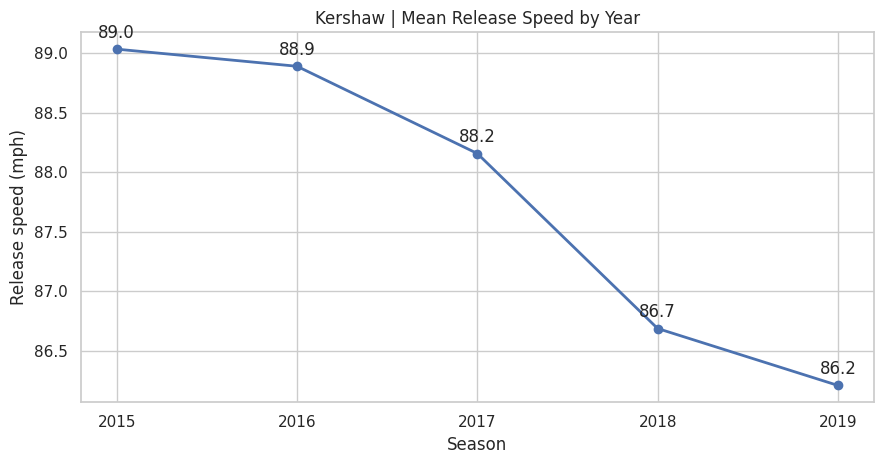

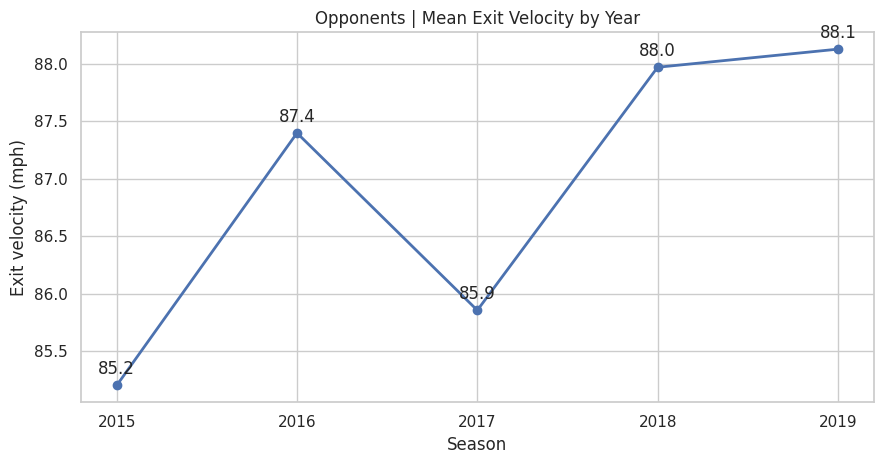

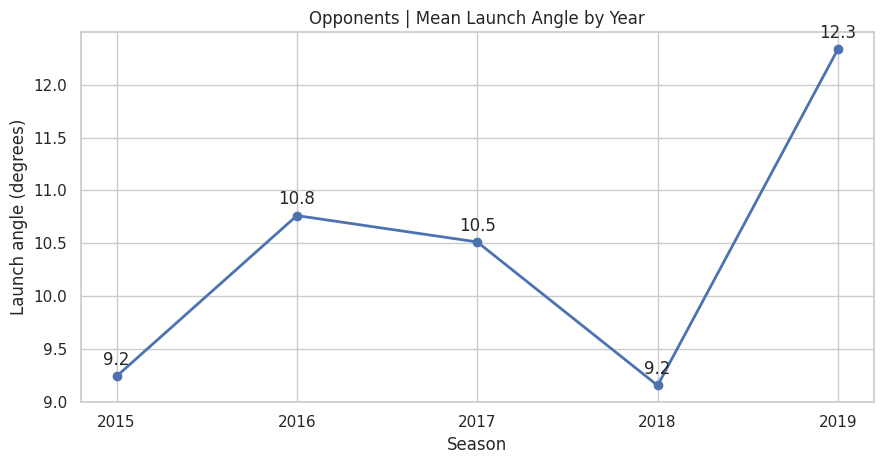

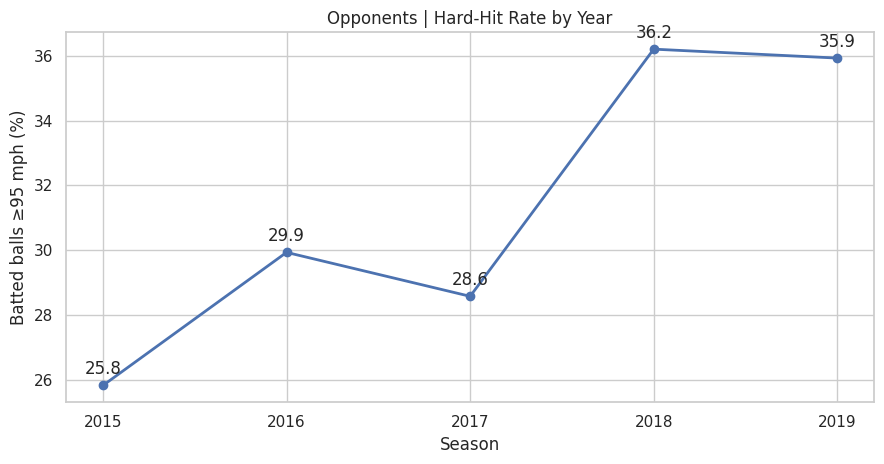

In [10]:
def plot_yearly_metric(table, column, title, ylabel, filename=None):
    series = table[column].dropna()
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(series.index, series.values, marker="o", linewidth=2)
    ax.set(xticks=list(YEARS), xlabel="Season", ylabel=ylabel, title=title)
    for year, value in series.items():
        ax.annotate(f"{value:.1f}", (year, value), xytext=(0, 8),
                    textcoords="offset points", ha="center")
    fig.tight_layout()
    if filename:
        fig.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

plot_yearly_metric(yearly, "avg_release_mph", "Kershaw | Mean Release Speed by Year",
                   "Release speed (mph)", "01_release_speed.png")
plot_yearly_metric(yearly, "avg_exit_velocity_mph", "Opponents | Mean Exit Velocity by Year",
                   "Exit velocity (mph)", "02_exit_velocity.png")
plot_yearly_metric(yearly, "avg_launch_angle_deg", "Opponents | Mean Launch Angle by Year",
                   "Launch angle (degrees)", "03_launch_angle.png")
plot_yearly_metric(yearly, "hard_hit_rate_pct", "Opponents | Hard-Hit Rate by Year",
                   "Batted balls ≥95 mph (%)", "04_hard_hit_rate.png")

## 4 · Game-level LOWESS trend plots


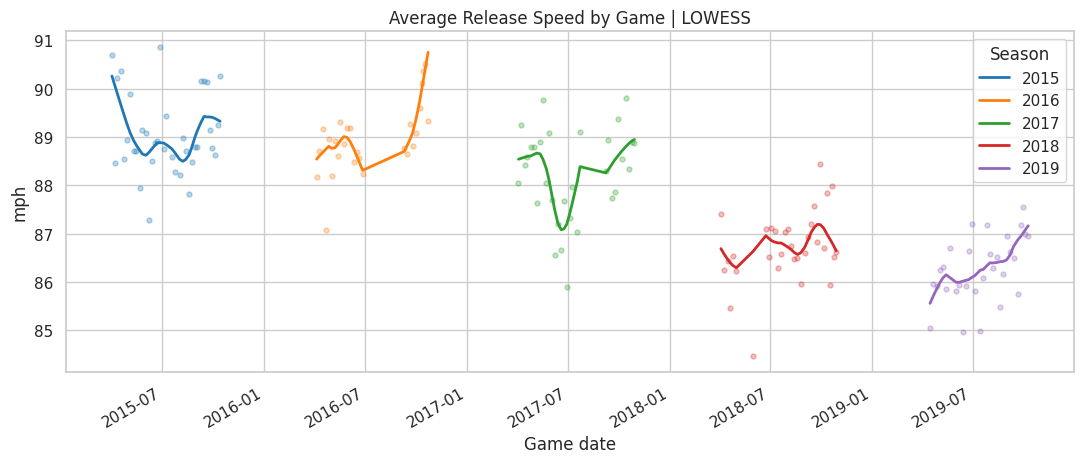

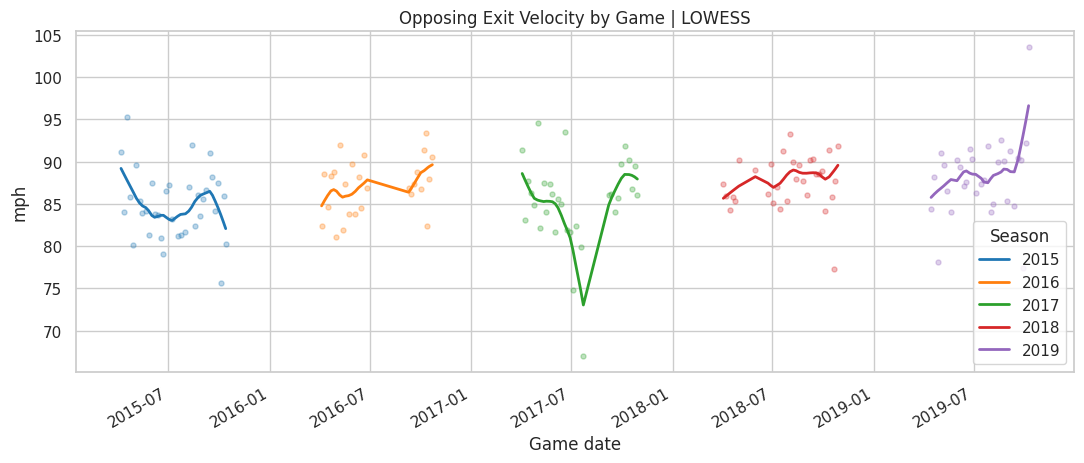

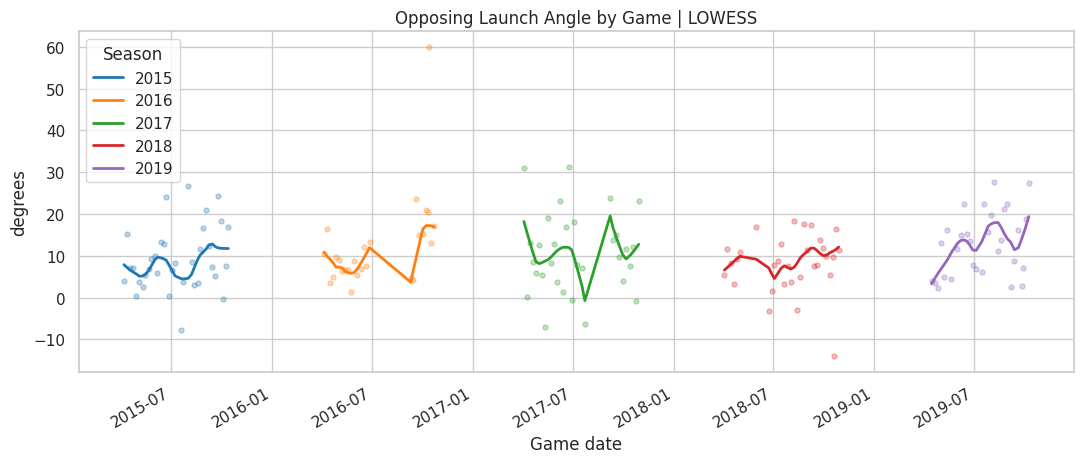

In [11]:
def plot_game_lowess(data, value_col, title, ylabel, frac=0.35):
    day_means = (data.dropna(subset=[value_col])
                 .groupby(["Year", "game_date"], as_index=False)[value_col].mean())
    fig, ax = plt.subplots(figsize=(11, 4.8))
    cmap = plt.get_cmap("tab10")
    for i, (year, part) in enumerate(day_means.groupby("Year")):
        part = part.sort_values("game_date")
        x = part["game_date"].map(pd.Timestamp.toordinal).to_numpy(dtype=float)
        y = part[value_col].to_numpy(dtype=float)
        color = cmap(i)
        ax.scatter(part["game_date"], y, s=13, alpha=0.30, color=color)
        if len(part) >= 5:
            smoothed = lowess(y, x, frac=frac, return_sorted=True)
            smooth_dates = [pd.Timestamp.fromordinal(int(d)) for d in smoothed[:, 0]]
            ax.plot(smooth_dates, smoothed[:, 1], linewidth=2, color=color, label=str(year))
        else:
            ax.plot(part["game_date"], y, label=str(year), color=color)
    ax.set(title=title, xlabel="Game date", ylabel=ylabel)
    ax.legend(title="Season")
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

plot_game_lowess(mechanics, "release_speed", "Average Release Speed by Game | LOWESS", "mph")
plot_game_lowess(batted_balls, "launch_speed", "Opposing Exit Velocity by Game | LOWESS", "mph")
plot_game_lowess(batted_balls, "launch_angle", "Opposing Launch Angle by Game | LOWESS", "degrees")

## 5 · Pitch mix and speed by pitch type

Overall average velocity can change simply because the **mix of fastballs, sliders, and curveballs changes**. Pitch-mix charts provide necessary context for interpreting the aggregate speed trend.

pitch_label,4-seam fastball,Changeup,Curveball,IN,Sinker,Slider
Year,,,,,,
2015,53.3,0.3,18.1,0.1,0.3,28.0
2016,50.9,0.3,15.4,0.1,1.0,32.3
2017,46.9,1.0,16.5,0.0,1.3,34.3
2018,41.2,0.4,16.6,0.0,0.2,41.5
2019,43.5,0.6,16.3,0.0,0.0,39.6


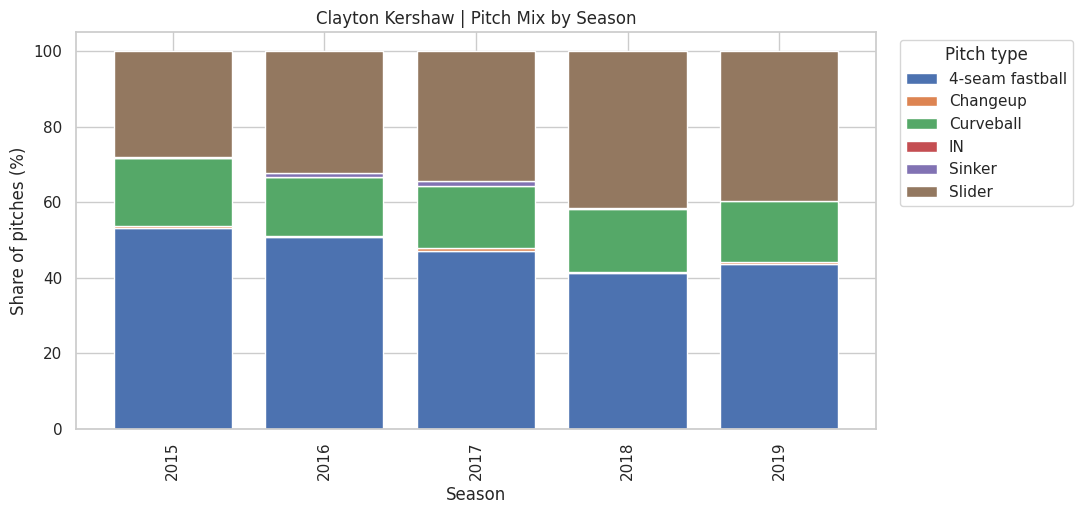

In [12]:
PITCH_NAMES = {"FF": "4-seam fastball", "SI": "Sinker", "FT": "2-seam fastball",
               "FC": "Cutter", "SL": "Slider", "CU": "Curveball", "KC": "Knuckle curve",
               "CH": "Changeup", "FS": "Splitter", "SC": "Screwball", "KN": "Knuckleball"}
mechanics["pitch_label"] = mechanics["pitch_type"].map(PITCH_NAMES).fillna(mechanics["pitch_type"])

mix_count = pd.crosstab(mechanics["Year"], mechanics["pitch_label"])
pitch_mix_pct = mix_count.div(mix_count.sum(axis=1), axis=0).mul(100)
display(pitch_mix_pct.round(1))
pitch_mix_pct.to_csv(OUTPUT_DIR / "kershaw_pitch_mix_percent.csv")

ax = pitch_mix_pct.plot(kind="bar", stacked=True, figsize=(11, 5.3), width=0.78)
ax.set(title="Clayton Kershaw | Pitch Mix by Season", xlabel="Season", ylabel="Share of pitches (%)")
ax.legend(title="Pitch type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_pitch_mix.png", dpi=180, bbox_inches="tight")
plt.show()

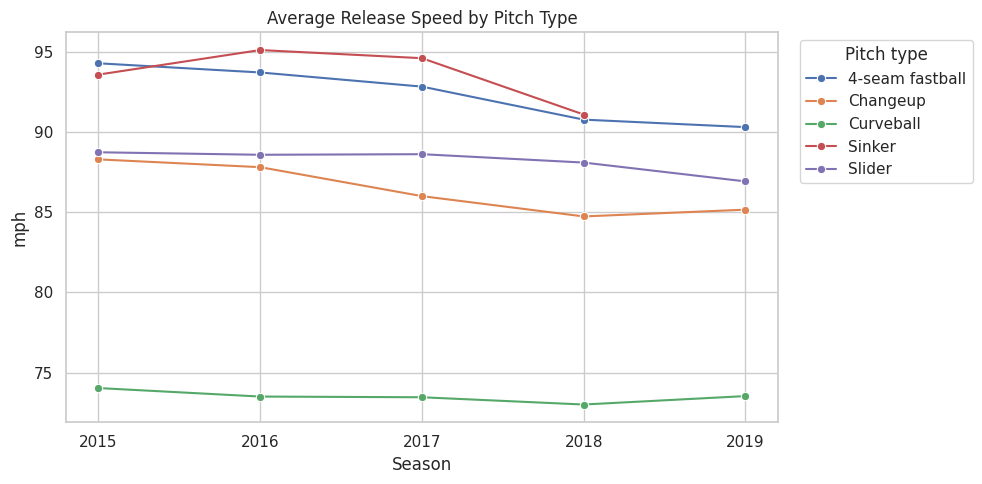

In [13]:
pitch_speed = (mechanics.groupby(["Year", "pitch_label"], as_index=False)
               .agg(avg_speed=("release_speed", "mean"), pitches=("release_speed", "count")))
# Avoid interpreting tiny pitch categories: plot types observed >= 50 times overall.
major_types = (pitch_speed.groupby("pitch_label")["pitches"].sum()
               .loc[lambda s: s >= 50].index)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=pitch_speed[pitch_speed["pitch_label"].isin(major_types)],
             x="Year", y="avg_speed", hue="pitch_label", marker="o", ax=ax)
ax.set(title="Average Release Speed by Pitch Type", xlabel="Season", ylabel="mph", xticks=list(YEARS))
ax.legend(title="Pitch type", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_speed_by_pitch.png", dpi=180, bbox_inches="tight")
plt.show()

## 6 · Horizontal and vertical pitch movement


,avg_horizontal_movement_ft,avg_vertical_movement_ft
Year,,
2015,-0.117,0.704
2016,-0.138,0.908
2017,-0.066,1.091
2018,-0.209,0.836
2019,-0.244,0.754


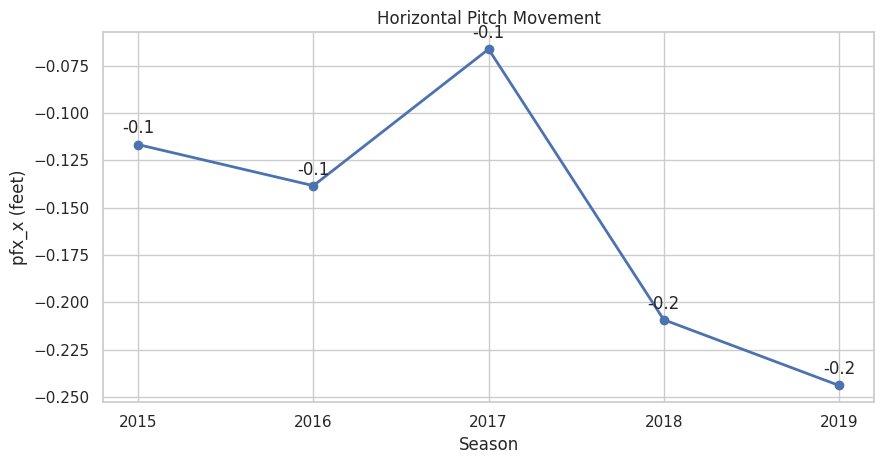

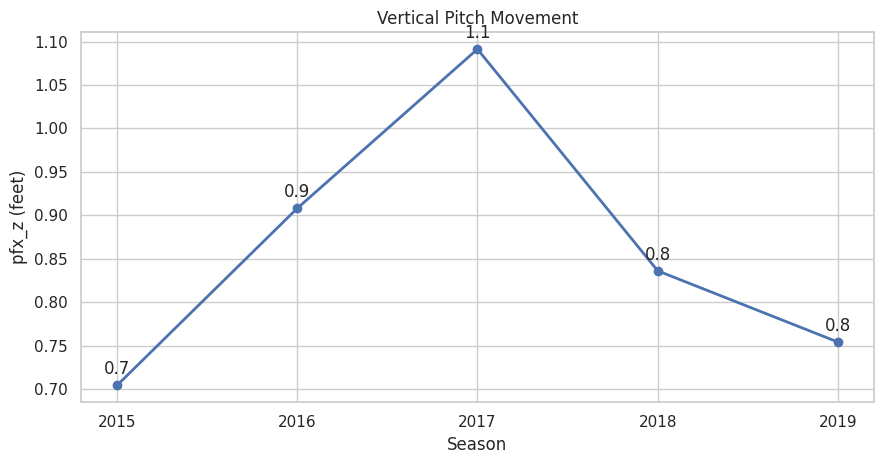

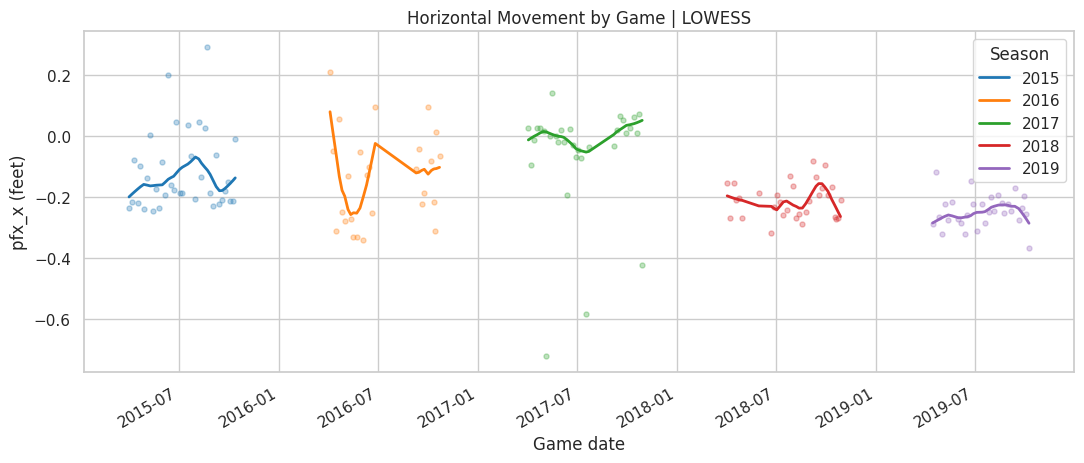

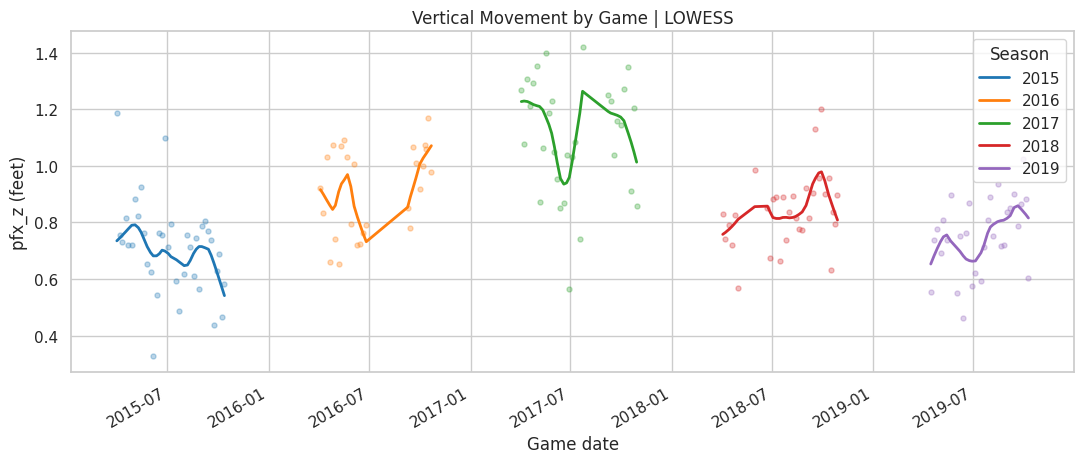

In [14]:
display(yearly[["avg_horizontal_movement_ft", "avg_vertical_movement_ft"]].round(3))
plot_yearly_metric(yearly, "avg_horizontal_movement_ft", "Horizontal Pitch Movement", "pfx_x (feet)")
plot_yearly_metric(yearly, "avg_vertical_movement_ft", "Vertical Pitch Movement", "pfx_z (feet)")
plot_game_lowess(mechanics, "pfx_x", "Horizontal Movement by Game | LOWESS", "pfx_x (feet)")
plot_game_lowess(mechanics, "pfx_z", "Vertical Movement by Game | LOWESS", "pfx_z (feet)")

## 7 · Pitch acceleration and initial velocity in three dimensions


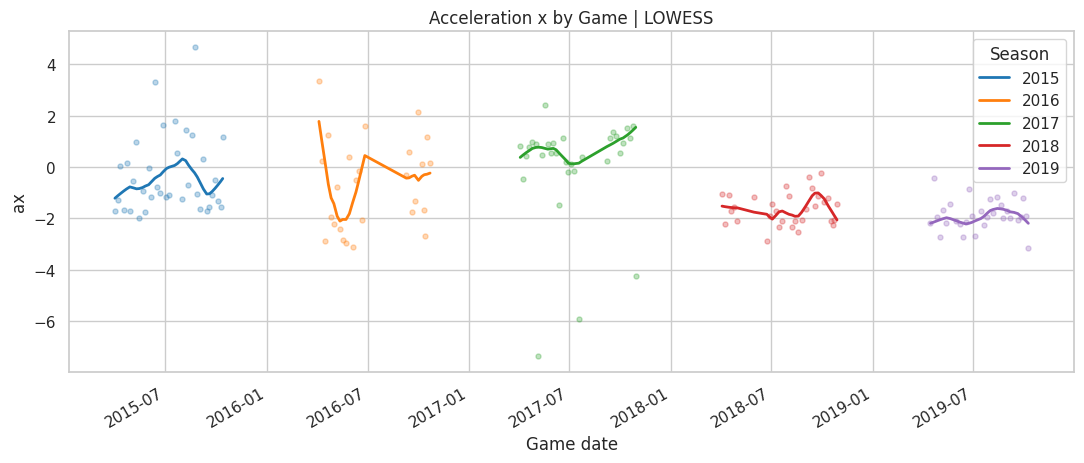

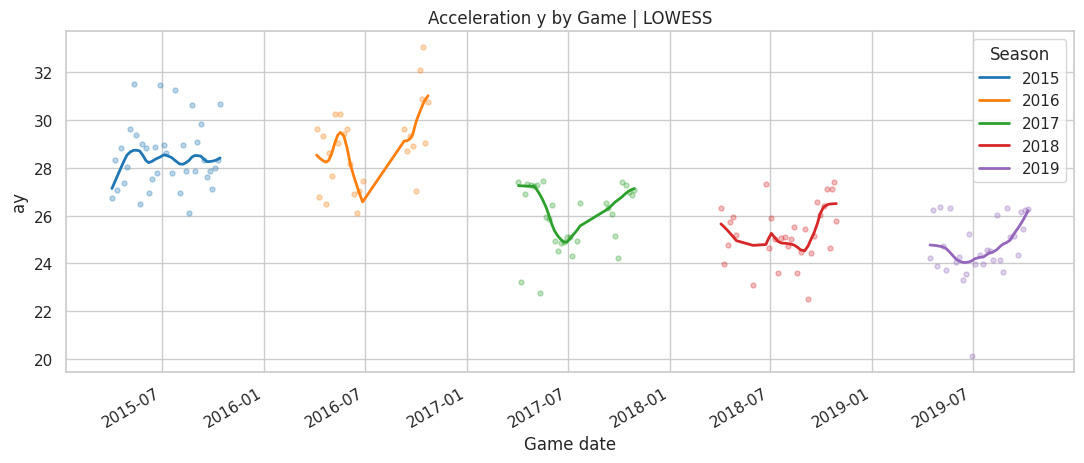

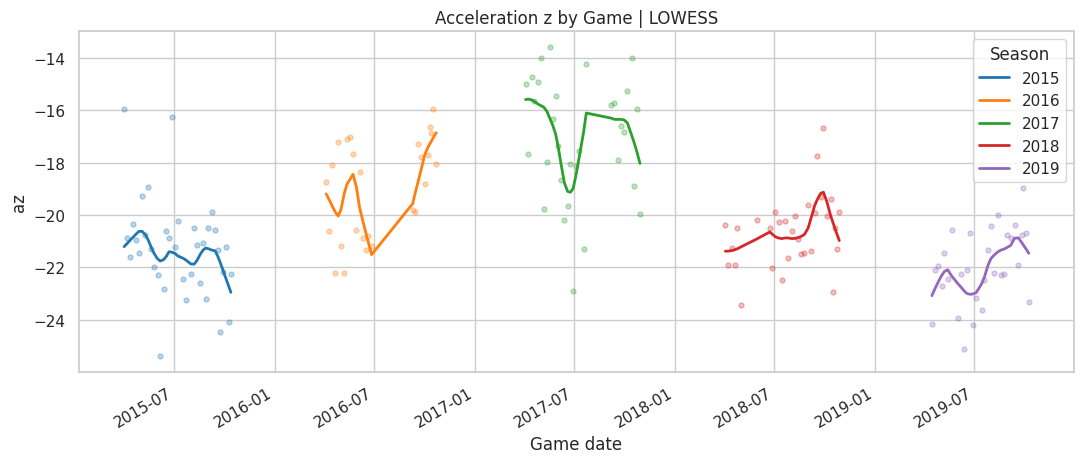

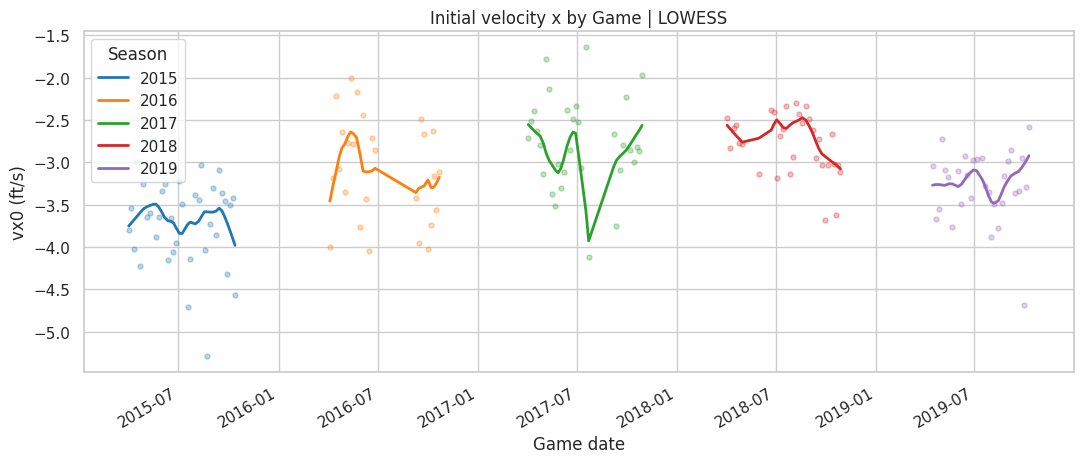

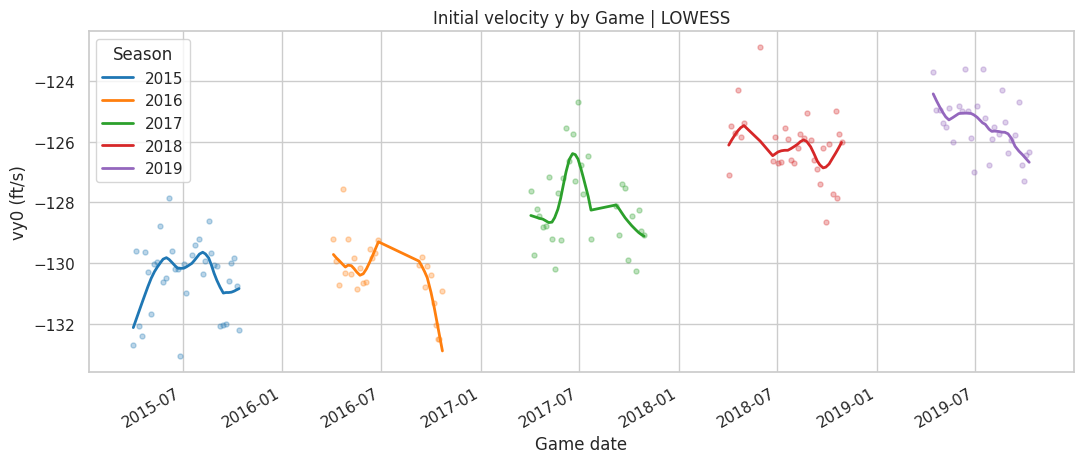

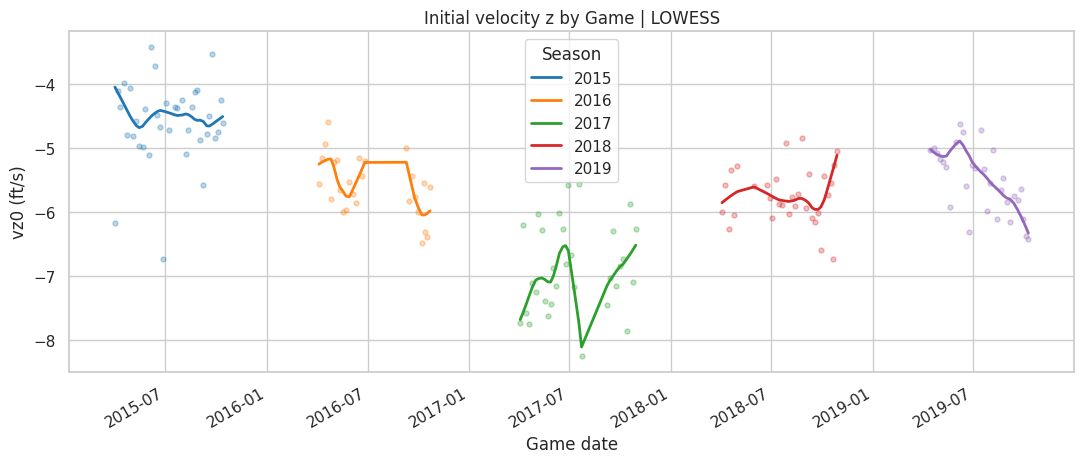

In [15]:
for column, label in [("ax", "Acceleration x"), ("ay", "Acceleration y"),
                      ("az", "Acceleration z")]:
    plot_game_lowess(mechanics, column, f"{label} by Game | LOWESS", column)

for column, label in [("vx0", "Initial velocity x"), ("vy0", "Initial velocity y"),
                      ("vz0", "Initial velocity z")]:
    plot_game_lowess(mechanics, column, f"{label} by Game | LOWESS", f"{column} (ft/s)")

## 8 · Pitch release position and interactive 3D view



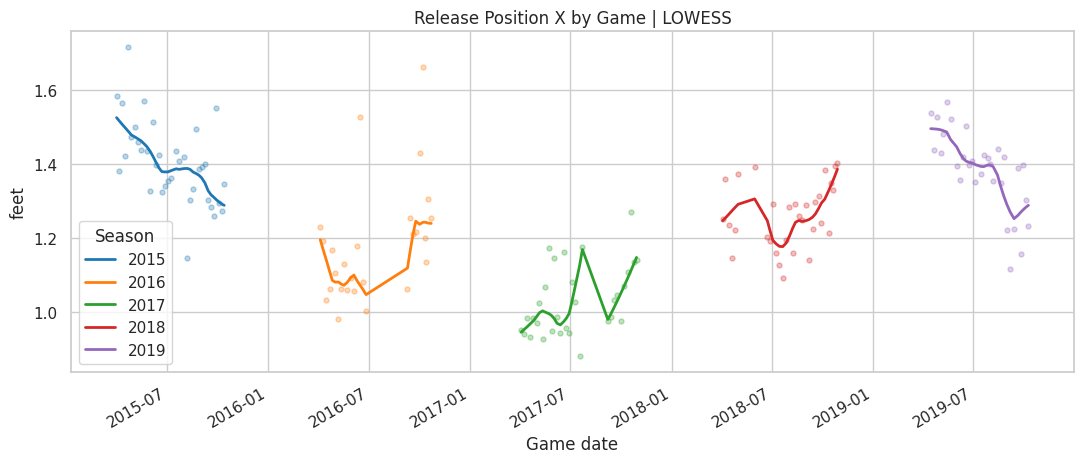

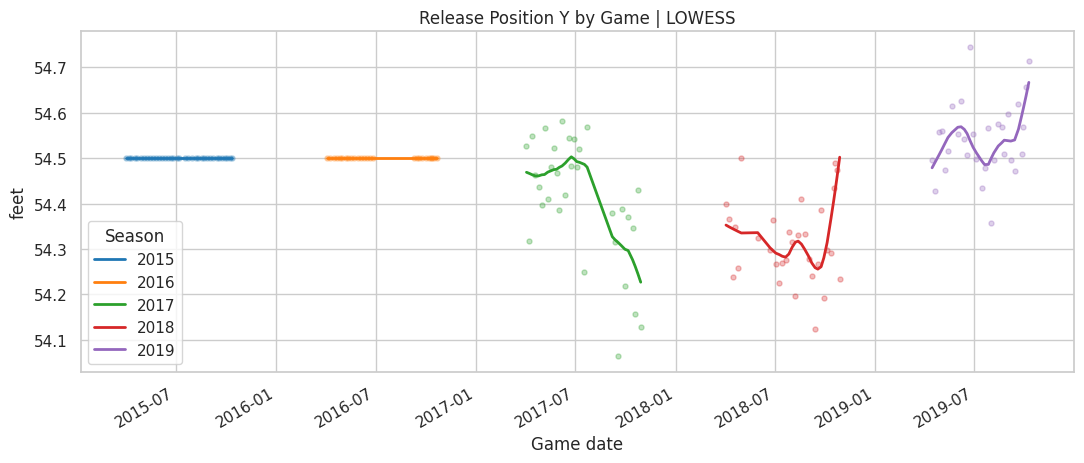

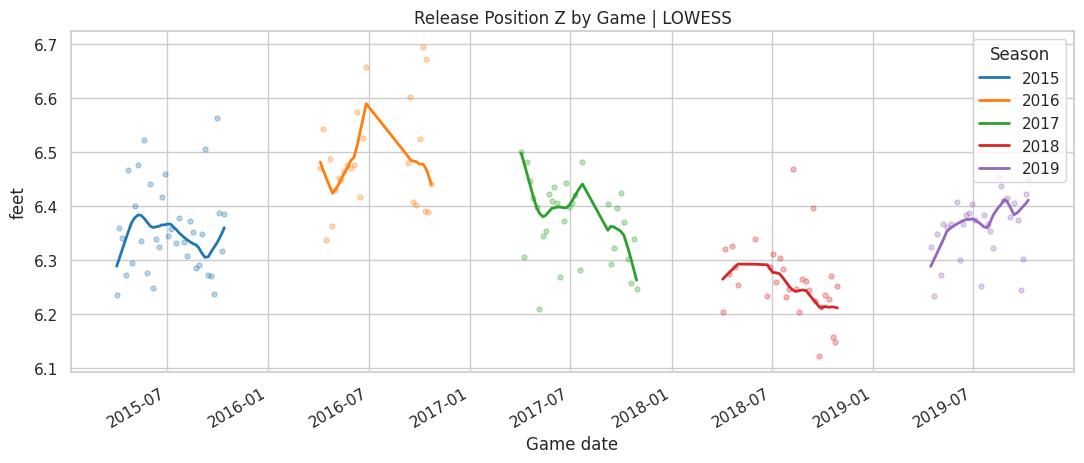

In [16]:
for column, axis in [("release_pos_x", "X"), ("release_pos_y", "Y"), ("release_pos_z", "Z")]:
    plot_game_lowess(mechanics, column, f"Release Position {axis} by Game | LOWESS", "feet")

release_cols = ["release_pos_x", "release_pos_y", "release_pos_z"]
daily_release = (mechanics.dropna(subset=release_cols)
                 .groupby(["Year", "game_date"], as_index=False)[release_cols].mean())
fig = px.scatter_3d(daily_release, x="release_pos_x", y="release_pos_y", z="release_pos_z",
                    color=daily_release["Year"].astype(str), hover_data=["game_date"],
                    title="Kershaw | Mean Pitch Release Position per Game")
fig.update_layout(legend_title_text="Season")
fig.show()

sample_release = mechanics.dropna(subset=release_cols)
if len(sample_release) > 5000:
    sample_release = sample_release.sample(n=5000, random_state=42)
fig_all = px.scatter_3d(sample_release, x="release_pos_x", y="release_pos_y",
                        z="release_pos_z", color=sample_release["Year"].astype(str),
                        title="Kershaw | Sample of Individual Pitch Release Positions",
                        opacity=0.55)
fig_all.update_layout(legend_title_text="Season")
fig_all.show()

## 9 · Pitch results (B/S/X) and plate-appearance outcomes


type,Ball,In play,Strike
Year,,,
2015,32.3,15.9,51.8
2016,31.1,17.4,51.5
2017,32.0,17.5,50.5
2018,31.6,19.4,49.0
2019,32.9,17.8,49.3


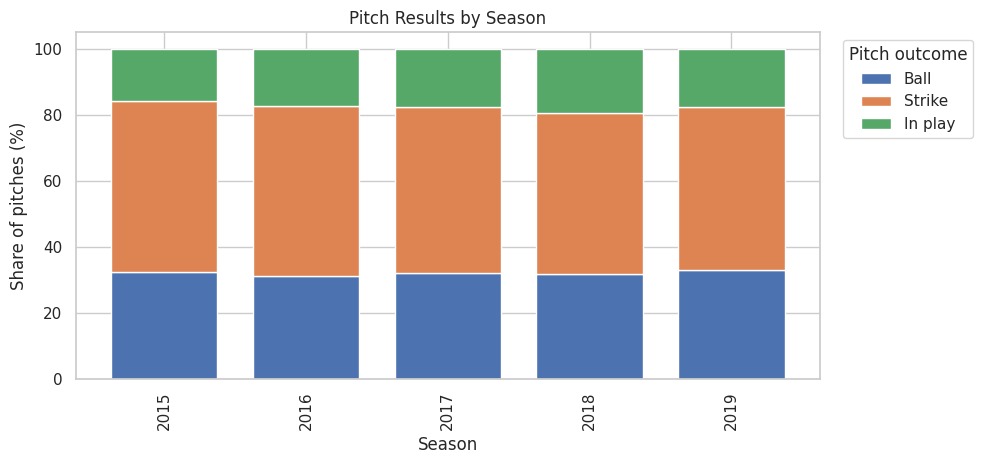

In [17]:
PITCH_OUTCOMES = {"B": "Ball", "S": "Strike", "X": "In play"}
pitch_results = pd.crosstab(all_pitches["Year"], all_pitches["type"].map(PITCH_OUTCOMES))
pitch_results_pct = pitch_results.div(pitch_results.sum(axis=1), axis=0).mul(100)
display(pitch_results_pct.round(1))
ax = pitch_results_pct.reindex(columns=["Ball", "Strike", "In play"], fill_value=0).plot(
    kind="bar", stacked=True, figsize=(10, 4.8), width=0.75)
ax.set(title="Pitch Results by Season", xlabel="Season", ylabel="Share of pitches (%)")
ax.legend(title="Pitch outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_pitch_results.png", dpi=180, bbox_inches="tight")
plt.show()

outcome_group,Strikeout,Field out,Hit (1B/2B/3B),Walk,Home run,Other
Year,,,,,,
2015,33.6,38.3,16.1,5.0,1.8,5.1
2016,31.1,43.2,17.2,2.2,1.5,4.8
2017,29.2,39.3,15.7,4.8,3.9,7.1
2018,23.5,44.2,18.3,4.4,2.7,6.9
2019,26.3,40.7,16.7,5.7,4.1,6.5


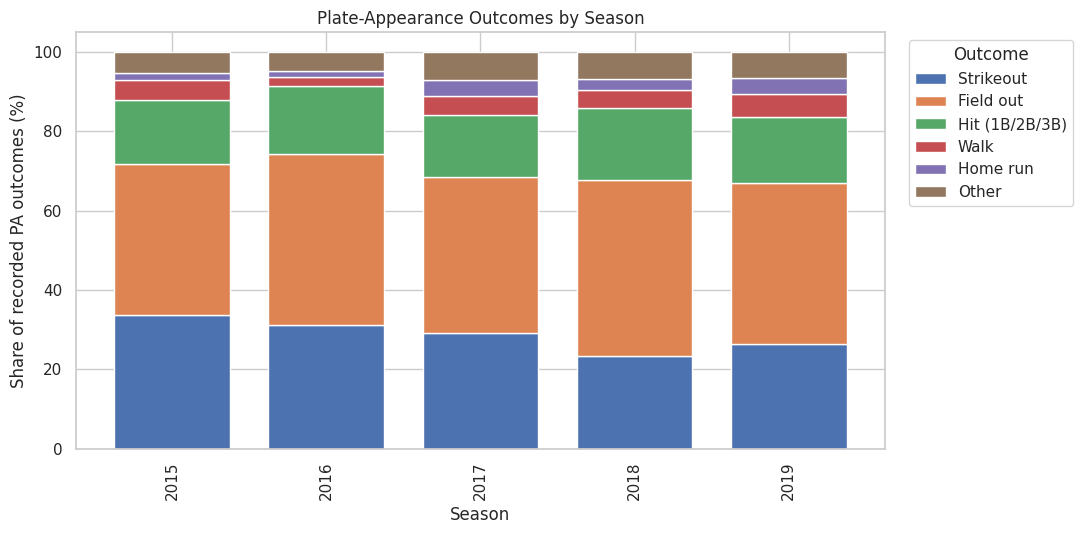

Share in exact report categories: 93.9%
'Other' includes other types of outs, reaching on error, hit-by-pitch, etc.; it is not solely on-base events.


In [18]:
EVENT_MAP = {
    "home_run": "Home run", "walk": "Walk", "strikeout": "Strikeout",
    "field_out": "Field out", "single": "Hit (1B/2B/3B)",
    "double": "Hit (1B/2B/3B)", "triple": "Hit (1B/2B/3B)",
}
plate_appearances["outcome_group"] = plate_appearances["events"].map(EVENT_MAP).fillna("Other")
event_counts = pd.crosstab(plate_appearances["Year"], plate_appearances["outcome_group"])
event_pct = event_counts.div(event_counts.sum(axis=1), axis=0).mul(100)
order = ["Strikeout", "Field out", "Hit (1B/2B/3B)", "Walk", "Home run", "Other"]
event_pct = event_pct.reindex(columns=order, fill_value=0)
display(event_pct.round(1))
ax = event_pct.plot(kind="bar", stacked=True, figsize=(11, 5.5), width=0.75)
ax.set(title="Plate-Appearance Outcomes by Season", xlabel="Season", ylabel="Share of recorded PA outcomes (%)")
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_pa_outcomes.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Share in exact report categories: {100 * (plate_appearances['outcome_group'] != 'Other').mean():.1f}%")
print("'Other' includes other types of outs, reaching on error, hit-by-pitch, etc.; it is not solely on-base events.")

hit_type,Double,Single,Triple
Year,,,
2015,16.9,81.8,1.3
2016,20.7,78.4,0.9
2017,16.9,81.5,1.6
2018,22.8,75.7,1.5
2019,21.1,76.4,2.4


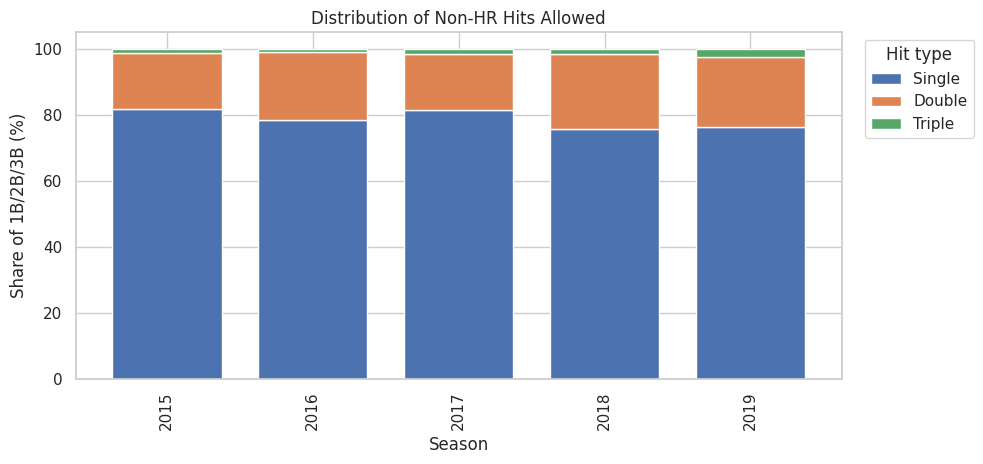

In [19]:
HIT_MAP = {"single": "Single", "double": "Double", "triple": "Triple"}
hit_events = plate_appearances.loc[plate_appearances["events"].isin(HIT_MAP)].copy()
hit_events["hit_type"] = hit_events["events"].map(HIT_MAP)
if hit_events.empty:
    print("No single/double/triple events available.")
else:
    hit_counts = pd.crosstab(hit_events["Year"], hit_events["hit_type"])
    hit_pct = hit_counts.div(hit_counts.sum(axis=1), axis=0).mul(100)
    display(hit_pct.round(1))
    ax = hit_pct.reindex(columns=["Single", "Double", "Triple"], fill_value=0).plot(
        kind="bar", stacked=True, figsize=(10, 4.8), width=0.75)
    ax.set(title="Distribution of Non-HR Hits Allowed", xlabel="Season", ylabel="Share of 1B/2B/3B (%)")
    ax.legend(title="Hit type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "09_hit_types.png", dpi=180, bbox_inches="tight")
    plt.show()

## 10 · Conclusions and limitations

Between 2015 and 2019, Clayton Kershaw experienced a decline in average pitch velocity, accompanied by an increase in opposing batters' exit velocity and hard-hit rate. During this period, he adjusted his pitch selection by reducing four-seam fastball usage and increasing slider usage. Strikeouts represented a smaller share of recorded plate appearances, while home runs represented a larger share. These trends suggest changing pitching effectiveness and an evolving approach to pitch selection, although the observational analysis cannot establish causation.